In [ ]:
import argparse
import numpy as np
import cv2
import subprocess
import os
import torch
import torch.nn.functional as F
from pathlib import Path
from typing import Tuple, List

# Paths  the model has been compiled by lynlang

print(os.getcwd())


WORK_DIR = os.getcwd() + "/../../model_files/spikeyolo_lynlang"
MODEL_DIR = WORK_DIR + "/Net_0" + "/apu_0"
print(MODEL_DIR)
import sys
import lyngor
lyngor_path = os.path.dirname(lyngor.__path__[0])
TEST_FPGA = lyngor_path + "/tvm/test_fpga"


/home/jing.zhang/anaconda3/envs/bidl
/home/jing.zhang/anaconda3/envs/bidl/lib/python3.8/site-packages/tvm/test_fpga


In [2]:
COCO_CLASSES = [
    'person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck',
    'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench',
    'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra',
    'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee',
    'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove',
    'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup',
    'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange',
    'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch',
    'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse',
    'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink',
    'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier',
    'toothbrush'
]
np.random.seed(42)
COLORS = [(int(r), int(g), int(b)) for r, g, b in np.random.randint(0, 255, (80, 3))]

In [3]:
def preprocess_image(image_path: str, target_size: Tuple[int, int] = (416, 416)):
    """
    Preprocess image with letterbox resize.

    Returns:
        original_img: Original BGR image
        input_data: Preprocessed NHWC float16 data
        transform: (scale, pad_x, pad_y, orig_w, orig_h) for box scaling
    """
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Failed to load image: {image_path}")

    original_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    orig_h, orig_w = img.shape[:2]
    target_h, target_w = target_size

    # Compute scale
    scale = min(target_w / orig_w, target_h / orig_h)
    new_w, new_h = int(orig_w * scale), int(orig_h * scale)

    # Resize
    img_resized = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)

    # Pad to target size
    img_padded = np.full((target_h, target_w, 3), 114, dtype=np.uint8)
    pad_x = (target_w - new_w) // 2
    pad_y = (target_h - new_h) // 2
    img_padded[pad_y:pad_y+new_h, pad_x:pad_x+new_w] = img_resized

    # Convert BGR to RGB and normalize
    img_rgb = cv2.cvtColor(img_padded, cv2.COLOR_BGR2RGB)
    img_normalized = img_rgb.astype(np.float32) / 255.0

    # Add batch dimension: [H, W, 3] -> [1, H, W, 3]
    input_data = img_normalized[np.newaxis, ...].astype(np.float16)

    transform = (scale, pad_x, pad_y, orig_w, orig_h)
    return original_img, input_data, transform


def run_fpga_inference(input_data: np.ndarray) -> List[Tuple[np.ndarray, int]]:
    """
    Run inference on FPGA using test_fpga.

    Returns:
        List of (detection_output, stride) tuples for P3, P4, P5
    """
    # Save input to model directory
    input_file = MODEL_DIR + "/case0/net0/chip0/tv_mem/data/input.dat"
    Path(input_file).parent.mkdir(parents=True, exist_ok=True)
    input_data.tofile(str(input_file))



    cmd = [TEST_FPGA, "-m", str(MODEL_DIR), "-l", "1", "--cm", "4"]   
    result = subprocess.run(cmd, capture_output=True, timeout=60)

    # Note: test_fpga may return non-zero even when inference succeeds (comparison fails)
    # We check for actual output files instead of return code

    # Load outputs - check multiple possible locations
    possible_outputs = [
        MODEL_DIR + "/data/output_ddr.dat",
        MODEL_DIR + "/case0/net0/chip0/tv_mem/data/output.dat",
    ]
    
    output_file = None
    for path in possible_outputs:
        print(path), print(Path(path).exists())
        if Path(path).exists() and Path(path).stat().st_size > 0:
            output_file = path
            break

    if output_file is None:
        print(f"Output file not found in any location")
        return []

    raw_output = np.fromfile(output_file, dtype=np.float16).astype(np.float32)
    print(f"  Loaded output from: {output_file}")
    print(f"  Output size: {len(raw_output)} elements ({len(raw_output)*2} bytes)")

    # Parse outputs: P3(52x52), P4(26x26), P5(13x13), each with 144 channels
    p3_size = 52 * 52 * 144
    p4_size = 26 * 26 * 144
    p5_size = 13 * 13 * 144
    expected_size = p3_size + p4_size + p5_size

    if len(raw_output) >= expected_size:
        p3 = raw_output[:p3_size].reshape(1, 52, 52, 144)
        p4 = raw_output[p3_size:p3_size+p4_size].reshape(1, 26, 26, 144)
        p5 = raw_output[p3_size+p4_size:p3_size+p4_size+p5_size].reshape(1, 13, 13, 144)
        return [(p3, 8), (p4, 16), (p5, 32)]
    elif len(raw_output) == p5_size:
        p5 = raw_output.reshape(1, 13, 13, 144)
        return [(p5, 32)]
    else:
        print(f"Unexpected output size: {len(raw_output)}, expected {expected_size}")
        return []


def dfl_decode(bbox_pred: torch.Tensor, reg_max: int = 16) -> torch.Tensor:
    """DFL decode: softmax + weighted sum"""
    N, H, W, C = bbox_pred.shape
    bbox_pred = bbox_pred.reshape(N, H, W, 4, reg_max)
    bbox_pred = F.softmax(bbox_pred, dim=-1)
    proj = torch.arange(reg_max, dtype=bbox_pred.dtype, device=bbox_pred.device)
    return (bbox_pred * proj).sum(dim=-1)


def make_anchors(H: int, W: int, stride: int) -> torch.Tensor:
    """Generate anchor points"""
    sy = torch.arange(H, dtype=torch.float32) + 0.5
    sx = torch.arange(W, dtype=torch.float32) + 0.5
    sy, sx = torch.meshgrid(sy, sx, indexing='ij')
    return torch.stack([sx, sy], dim=-1).reshape(-1, 2) * stride


def nms(boxes: np.ndarray, scores: np.ndarray, thresh: float = 0.45) -> List[int]:
    """Non-Maximum Suppression"""
    if len(boxes) == 0:
        return []

    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    areas = (x2 - x1) * (y2 - y1)
    order = scores.argsort()[::-1]

    keep = []
    while order.size > 0:
        i = order[0]
        keep.append(i)
        if order.size == 1:
            break

        xx1 = np.maximum(x1[i], x1[order[1:]])
        yy1 = np.maximum(y1[i], y1[order[1:]])
        xx2 = np.minimum(x2[i], x2[order[1:]])
        yy2 = np.minimum(y2[i], y2[order[1:]])

        inter = np.maximum(0, xx2 - xx1) * np.maximum(0, yy2 - yy1)
        iou = inter / (areas[i] + areas[order[1:]] - inter + 1e-6)
        order = order[np.where(iou <= thresh)[0] + 1]

    return keep


def postprocess(det_outputs: List[Tuple[np.ndarray, int]],
                conf_thresh: float = 0.25,
                iou_thresh: float = 0.45,
                max_det: int = 300) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """
    Post-process detection outputs.
    Note: Sigmoid is already applied in hardware (LynLang).
    """
    all_boxes, all_scores, all_cls = [], [], []

    for det, stride in det_outputs:
        N, H, W, C = det.shape
        det_tensor = torch.from_numpy(det)

        # DFL decode for bbox
        bbox_decoded = dfl_decode(det_tensor[..., :64])  # [1, H, W, 4]

        # Generate anchors
        anchors = make_anchors(H, W, stride)  # [H*W, 2]

        # Flatten
        bbox_flat = bbox_decoded.reshape(-1, 4) * stride  # [H*W, 4]
        cls_flat = det_tensor[..., 64:].reshape(-1, 80)  # [H*W, 80] - already sigmoid!

        # Convert ltrb to xyxy: box = [anchor - lt, anchor + rb]
        lt, rb = bbox_flat[:, :2], bbox_flat[:, 2:]
        boxes = torch.cat([anchors - lt, anchors + rb], dim=1)  # [H*W, 4]

        # Filter by confidence (per class)
        for c in range(80):
            mask = cls_flat[:, c] > conf_thresh
            if mask.sum() > 0:
                all_boxes.append(boxes[mask].numpy())
                all_scores.append(cls_flat[mask, c].numpy())
                all_cls.append(np.full(mask.sum().item(), c))

    if not all_boxes:
        return np.array([]), np.array([]), np.array([])

    # Concatenate
    boxes = np.clip(np.concatenate(all_boxes), 0, 416)
    scores = np.concatenate(all_scores)
    cls_ids = np.concatenate(all_cls).astype(int)

    # NMS per class
    final_boxes, final_scores, final_cls = [], [], []
    for c in np.unique(cls_ids):
        mask = cls_ids == c
        keep = nms(boxes[mask], scores[mask], iou_thresh)
        if keep:
            final_boxes.append(boxes[mask][keep])
            final_scores.append(scores[mask][keep])
            final_cls.append(np.full(len(keep), c))

    if not final_boxes:
        return np.array([]), np.array([]), np.array([])

    boxes = np.concatenate(final_boxes)
    scores = np.concatenate(final_scores)
    cls_ids = np.concatenate(final_cls).astype(int)

    # Limit detections
    if len(scores) > max_det:
        idx = np.argsort(scores)[::-1][:max_det]
        boxes, scores, cls_ids = boxes[idx], scores[idx], cls_ids[idx]

    return boxes, scores, cls_ids


def scale_boxes(boxes: np.ndarray, transform: Tuple) -> np.ndarray:
    """Scale boxes back to original image coordinates"""
    if len(boxes) == 0:
        return boxes

    scale, pad_x, pad_y, orig_w, orig_h = transform
    boxes = boxes.copy()
    boxes[:, [0, 2]] = np.clip((boxes[:, [0, 2]] - pad_x) / scale, 0, orig_w)
    boxes[:, [1, 3]] = np.clip((boxes[:, [1, 3]] - pad_y) / scale, 0, orig_h)
    return boxes


In [4]:
def draw_detections(img: np.ndarray, boxes: np.ndarray,
                   scores: np.ndarray, cls_ids: np.ndarray) -> np.ndarray:
    """Draw detection boxes on image"""
    img = img.copy()

    for box, score, cls_id in zip(boxes, scores, cls_ids):
        x1, y1, x2, y2 = box.astype(int)
        color = COLORS[cls_id % len(COLORS)]
        label = f"{COCO_CLASSES[cls_id]}: {score:.2f}"

        # Draw box
        cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)

        # Draw label background
        (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
        cv2.rectangle(img, (x1, y1 - th - 8), (x1 + tw + 4, y1), color, -1)

        # Draw label text
        cv2.putText(img, label, (x1 + 2, y1 - 4),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

    return img


TK_INFO: test_fpga cmd: /home/jing.zhang/anaconda3/envs/bidl/lib/python3.8/site-packages/tvm/test_fpga -m ./lynlang/Net_0/apu_0 -l 1 --cm 4
TK_INFO: test_fpga version 1.1.37
TK_WARN: set thread time 1800s over it will force exit
TK_Err : errmsg: [13] Permission denied.

TK_Err : open /tmp/fpga.lock fail.

TK_INFO: case path is ./lynlang/Net_0/apu_0
TK_INFO: device ID is 0
TK_Info: 1 extra ddr input added
TK_Info: 1 extra ddr output added
TK_Info: ====================Git Version info Lynabc_hw3_8896================================
TK_Info: pausePhase：1228
TK_INFO: setCfg, input path: ./lynlang/Net_0/apu_0/case0/net0/chip0/tv_mem/data
TK_INFO: setCfg, inputDataPath: ./lynlang/Net_0/apu_0/case0/net0/chip0/tv_mem/data/../../../../../apu_x/lookup_ddr_addr.bin
TK_Err : errmsg: [13] Permission denied.

TK_Err : open /tmp/fpga.lock fail.

TK_INFO: chipver: CHIPVER_KA200
TK_Info: 0 LYN PCI devices found, open first device 0 successfully.

	runSuperCmd built: Jul 31 2025 22:33:14
TK_INFO: coreNu

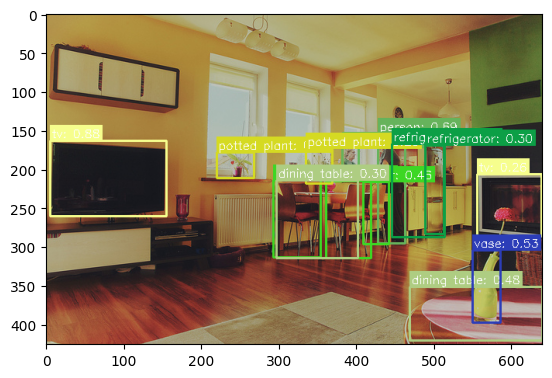

In [5]:
import matplotlib.pyplot as plt
input_img = "000000000139.jpg"
original_img, input_data, transform = preprocess_image(input_img)
det_outputs = run_fpga_inference(input_data)
if not det_outputs:
    print("  ERROR: No detection outputs!")
    exit()
print(f"  Got {len(det_outputs)} detection scales")
for det, stride in det_outputs:
    print(f"    - Shape: {det.shape}, stride: {stride}")
boxes, scores, cls_ids = postprocess(det_outputs, 0.25, 0.45)
boxes = scale_boxes(boxes, transform)
print(f"  Detections: {len(boxes)}")
result_img = draw_detections(original_img, boxes, scores, cls_ids)

plt.imshow(result_img)


